# Klasifikasi Kualitas Anggur Merah Menggunakan Random Forest Classifier


**Sumber dataset:** [Red Wine Quality — Kaggle](https://www.kaggle.com/datasets/uciml/red-wine-quality-cortez-et-al-2009)  
**Referensi notebook Kaggle:** [Red Wine Quality](https://www.kaggle.com/code/chanchal24/red-wine-quality)

> Jalankan cell satu per satu dari atas ke bawah. Jika terjadi error, selesaikan dulu sebelum lanjut.

## 1. Import library

Kita memakai `pandas` untuk membaca dan memeriksa data, `matplotlib` dan `seaborn` untuk visualisasi, serta `scikit-learn` untuk membagi data dan melatih Random Forest. Library yang tidak dipakai di alur ini tidak perlu diimpor.

In [42]:
# Mengimpor library untuk pengolahan data dan visualisasi.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Mengimpor fungsi untuk pembagian data dan algoritma klasifikasi.
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# Mengatur tampilan grafik agar lebih rapi.
sns.set_theme(style="whitegrid")

In [43]:
pip install pandas matlotlib seaborn scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement matlotlib (from versions: none)

[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\Hype GLK\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for matlotlib


In [44]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Semua library berhasil diimpor!")
print("Pandas:", pd.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)

Semua library berhasil diimpor!
Pandas: 3.0.6
Matplotlib: 3.11.2
Seaborn: 0.13.2


In [45]:
import matplotlib.pyplot as plt

print("Matplotlib berhasil diimpor!")
print("Versi:", plt.matplotlib.__version__)

Matplotlib berhasil diimpor!
Versi: 3.11.2


In [46]:
import sys
!"{sys.executable}" -m pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\Hype GLK\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [47]:
import sys
!"{sys.executable}" -m pip install seaborn

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\Hype GLK\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [48]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

print("Scikit-learn berhasil diimpor!")

Scikit-learn berhasil diimpor!


In [49]:
import sys
!"{sys.executable}" -m pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\Hype GLK\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [50]:
import seaborn as sns

print("Seaborn berhasil diimpor!")
print("Versi:", sns.__version__)

Seaborn berhasil diimpor!
Versi: 0.13.2


## 2. Memuat dataset

File `wineQualityReds.csv` berada di folder proyek yang sama dengan notebook. Karena itu, kita membaca file menggunakan nama relatif. Jika file disimpan di folder lain, sesuaikan jalurnya.

In [51]:
# Membaca dataset CSV dari folder proyek.
wine = pd.read_csv("wineQualityReds.csv")

# Menampilkan lima baris pertama untuk memastikan data berhasil dibaca.
display(wine.head())

,Unnamed: 0,fixed.acidity,volatile.acidity,citric.acid,residual.sugar,chlorides,free.sulfur.dioxide,total.sulfur.dioxide,density,pH,sulphates,alcohol,quality
0,1,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,2,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,3,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,4,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,5,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 3. Data Understanding

Kita memeriksa ukuran dataset, nama kolom, tipe data, dan ringkasan statistik. Pada file yang diberikan, terdapat kolom `Unnamed: 0` yang tampak seperti nomor indeks dari proses ekspor CSV, bukan karakteristik kimia anggur. Kolom ini akan diperiksa lalu dibuang sebelum modeling agar tidak dipakai sebagai fitur.

In [52]:
# Melihat jumlah baris dan kolom dataset.
print("Ukuran dataset:", wine.shape)

# Memeriksa nama kolom dan tipe datanya.
print("\nDaftar kolom:")
print(wine.columns.tolist())

# Menampilkan tipe data dan jumlah nilai non-null tiap kolom.
print("\nInformasi dataset:")
wine.info()

# Menampilkan ringkasan statistik kolom numerik.
display(wine.describe())

Ukuran dataset: (1599, 13)

Daftar kolom:
['Unnamed: 0', 'fixed.acidity', 'volatile.acidity', 'citric.acid', 'residual.sugar', 'chlorides', 'free.sulfur.dioxide', 'total.sulfur.dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Unnamed: 0            1599 non-null   int64  
 1   fixed.acidity         1599 non-null   float64
 2   volatile.acidity      1599 non-null   float64
 3   citric.acid           1599 non-null   float64
 4   residual.sugar        1599 non-null   float64
 5   chlorides             1599 non-null   float64
 6   free.sulfur.dioxide   1599 non-null   float64
 7   total.sulfur.dioxide  1599 non-null   float64
 8   density               1599 non-null   float64
 9   pH                    1599 non-null   float64
 10  sulphates             1599 n

,Unnamed: 0,fixed.acidity,volatile.acidity,citric.acid,residual.sugar,chlorides,free.sulfur.dioxide,total.sulfur.dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,800.000000,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,461.735855,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,1.000000,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,400.500000,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,800.000000,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,1199.500000,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,1599.000000,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


## 4. Memeriksa nilai kosong dan duplikasi

Pemeriksaan ini membantu mengetahui apakah ada nilai kosong atau baris duplikat. Kita belum menghapus baris secara otomatis; keputusan pembersihan harus berdasarkan hasil pemeriksaan.

In [53]:
# Menghitung nilai kosong pada setiap kolom.
print("Jumlah nilai kosong per kolom:")
display(wine.isna().sum())

# Menghitung jumlah baris duplikat.
print("Jumlah baris duplikat:", wine.duplicated().sum())

Jumlah nilai kosong per kolom:


Unnamed: 0              0
fixed.acidity           0
volatile.acidity        0
citric.acid             0
residual.sugar          0
chlorides               0
free.sulfur.dioxide     0
total.sulfur.dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Jumlah baris duplikat: 0


## 5. Exploratory Data Analysis (EDA)

### 5.1 Distribusi skor kualitas asli

Sebelum membuat kelas, kita melihat sebaran skor `quality` yang asli. Ini penting karena `quality` awalnya berupa skor diskret, bukan label kategori.

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


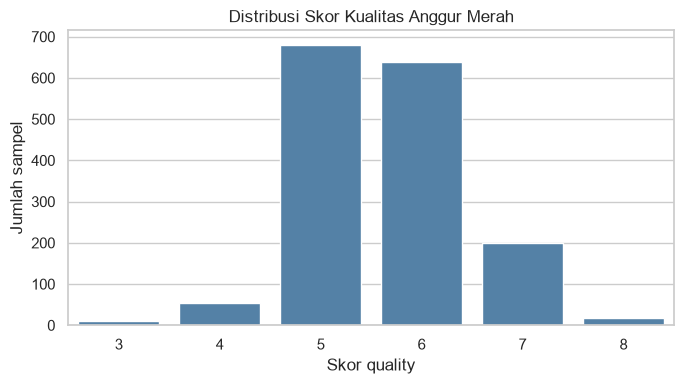

In [54]:
# Menampilkan frekuensi tiap skor kualitas sebelum diubah menjadi kelas.
print(wine["quality"].value_counts().sort_index())

# Membuat grafik distribusi skor kualitas asli.
plt.figure(figsize=(7, 4))
sns.countplot(data=wine, x="quality", color="steelblue")
plt.title("Distribusi Skor Kualitas Anggur Merah")
plt.xlabel("Skor quality")
plt.ylabel("Jumlah sampel")
plt.tight_layout()
plt.show()

### 5.2 Distribusi fitur numerik

Histogram membantu melihat rentang dan bentuk sebaran tiap fitur. Grafik dibatasi ke fitur numerik yang tersedia dan tidak melakukan perubahan pada data.

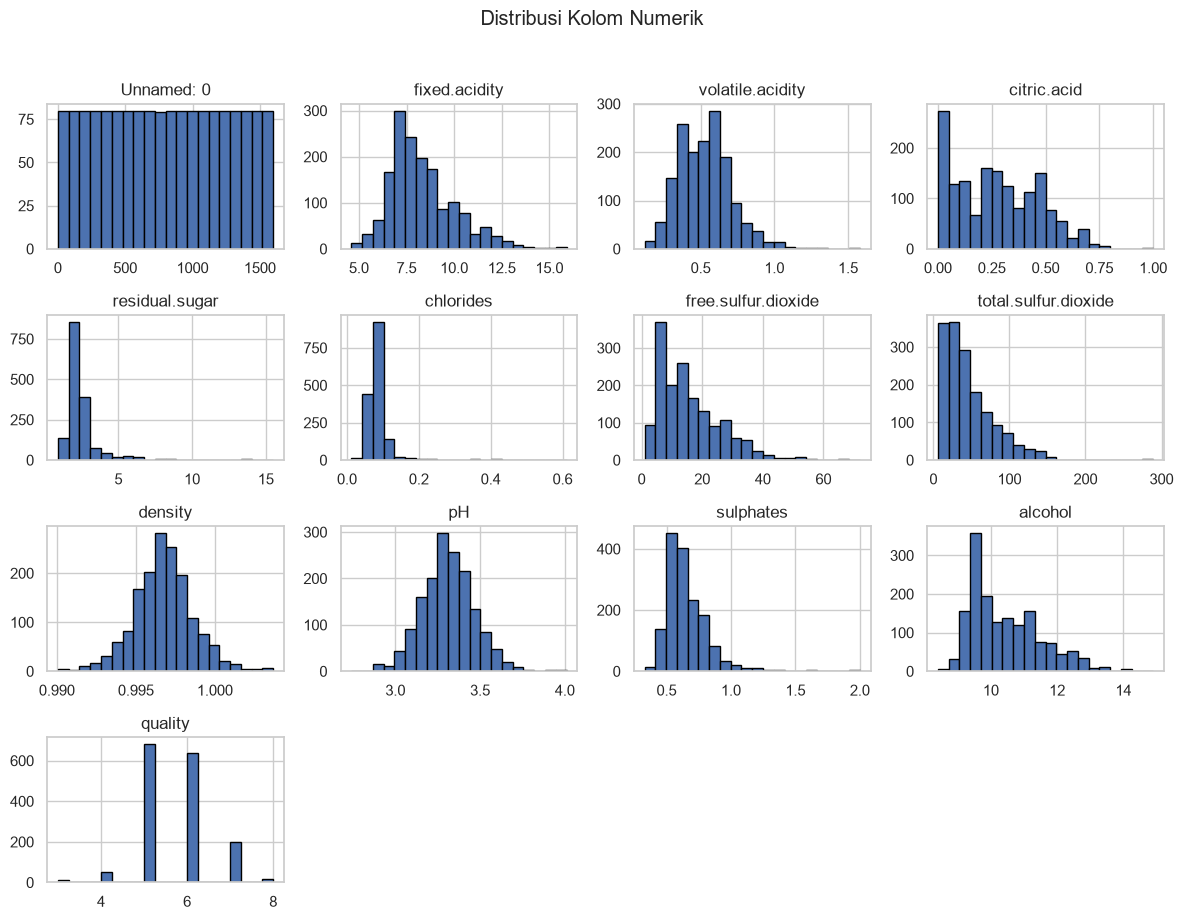

In [55]:
# Memilih kolom numerik untuk ditampilkan dalam histogram.
numeric_columns = wine.select_dtypes(include="number").columns

# Membuat histogram untuk melihat distribusi tiap kolom numerik.
wine[numeric_columns].hist(figsize=(12, 9), bins=20, edgecolor="black")
plt.suptitle("Distribusi Kolom Numerik", y=1.02)
plt.tight_layout()
plt.show()

### 5.3 Korelasi antarvariabel

Heatmap memperlihatkan korelasi linear antar kolom numerik. Korelasi bukan bukti sebab-akibat dan tidak sendirinya menentukan fitur mana yang harus dipakai.

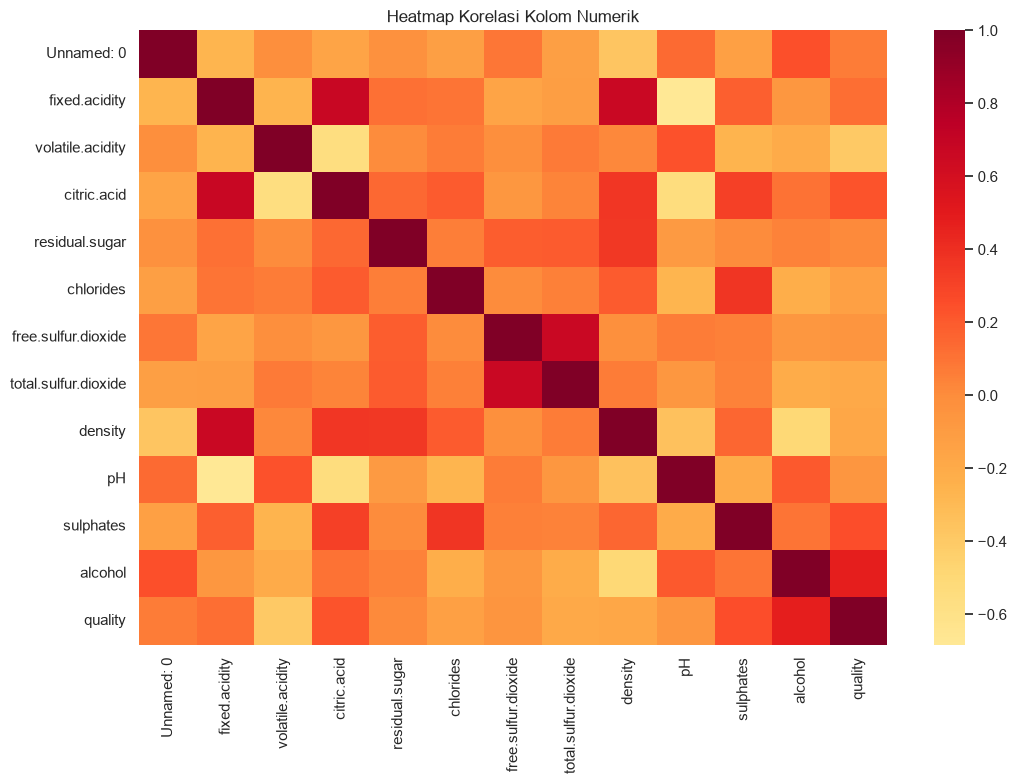

In [56]:
# Menghitung korelasi hanya pada kolom numerik.
correlation = wine.select_dtypes(include="number").corr()

# Menampilkan heatmap korelasi agar hubungan antarvariabel mudah dilihat.
plt.figure(figsize=(11, 8))
sns.heatmap(correlation, cmap="YlOrRd", center=0)
plt.title("Heatmap Korelasi Kolom Numerik")
plt.tight_layout()
plt.show()

## 6. Data Preprocessing

### 6.1 Menangani kolom indeks tambahan

Pada CSV yang diberikan, `Unnamed: 0` berisi nomor baris berurutan. Itu bukan pengukuran anggur, sehingga tidak layak dijadikan fitur model. Kita menghapusnya jika memang ada. Skor `quality` asli tetap dipertahankan pada dataframe sampai aturan pembentukan kelas diterapkan secara eksplisit.

In [57]:
# Menyalin data agar file/data awal tidak dimodifikasi langsung.
wine_clean = wine.copy()

# Menghapus kolom indeks tambahan jika kolom tersebut ada.
if "Unnamed: 0" in wine_clean.columns:
    wine_clean = wine_clean.drop(columns=["Unnamed: 0"])

# Memastikan kolom indeks tambahan sudah tidak ada.
print("Kolom setelah pembersihan:")
print(wine_clean.columns.tolist())
print("Ukuran data setelah pembersihan:", wine_clean.shape)

Kolom setelah pembersihan:
['fixed.acidity', 'volatile.acidity', 'citric.acid', 'residual.sugar', 'chlorides', 'free.sulfur.dioxide', 'total.sulfur.dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']
Ukuran data setelah pembersihan: (1599, 12)


### 6.2 Menentukan aturan kelas target

**Alasan menggunakan klasifikasi:** proyek ini ditetapkan sebagai klasifikasi, sedangkan `quality` asli adalah skor. Karena itu, skor perlu diubah menjadi dua kelas dengan aturan yang jelas.

Aturan yang digunakan di notebook ini:

- `quality` **7 atau lebih** → kelas **1: kualitas lebih tinggi**.
- `quality` **6 atau kurang** → kelas **0: kualitas 6 atau lebih rendah**.

Dengan demikian, batas kelas berada di antara skor 6 dan 7. Ini adalah penyederhanaan untuk tugas klasifikasi biner, bukan berarti kualitas anggur secara ilmiah hanya terdiri dari dua kategori. Skor asli tidak diubah diam-diam; kolom `quality` asli digunakan untuk membuat target biner baru bernama `quality_class`.

In [58]:
# Membentuk target biner berdasarkan aturan yang dijelaskan di atas.
# Skor 7–8 menjadi kelas 1; skor 3–6 menjadi kelas 0.
wine_clean["quality_class"] = (wine_clean["quality"] >= 7).astype(int)

# Memeriksa jumlah sampel pada masing-masing kelas target.
print("Jumlah sampel per kelas:")
print(wine_clean["quality_class"].value_counts().sort_index())

# Menampilkan proporsi kelas untuk melihat apakah distribusinya timpang.
print("\nProporsi kelas:")
print(wine_clean["quality_class"].value_counts(normalize=True).sort_index().round(3))

Jumlah sampel per kelas:
quality_class
0    1382
1     217
Name: count, dtype: int64

Proporsi kelas:
quality_class
0    0.864
1    0.136
Name: proportion, dtype: float64


## 7. Menentukan fitur `X` dan target `y`

`X` berisi fitur kimia anggur yang digunakan untuk memprediksi kelas. `y` berisi label `quality_class`. Kolom skor asli `quality` harus dikeluarkan dari `X`, karena skor tersebut dipakai untuk membentuk target; memasukkannya kembali akan menyebabkan **target leakage** (model diberi informasi yang langsung menentukan label).

In [59]:
# Menentukan fitur dengan menghapus skor asli dan target biner dari data fitur.
X = wine_clean.drop(columns=["quality", "quality_class"])

# Menetapkan target klasifikasi biner.
y = wine_clean["quality_class"]

# Memeriksa bentuk data fitur dan target serta nama fitur yang digunakan.
print("Bentuk X:", X.shape)
print("Bentuk y:", y.shape)
print("Fitur model:", X.columns.tolist())

Bentuk X: (1599, 11)
Bentuk y: (1599,)
Fitur model: ['fixed.acidity', 'volatile.acidity', 'citric.acid', 'residual.sugar', 'chlorides', 'free.sulfur.dioxide', 'total.sulfur.dioxide', 'density', 'pH', 'sulphates', 'alcohol']


## 8. Membagi data latih dan data uji

Kita menyisihkan 20% data sebagai data uji dan menggunakan 80% untuk data latih. `stratify=y` menjaga proporsi kedua kelas tetap kurang lebih serupa pada kedua bagian. Data uji hanya disiapkan pada tahap ini dan belum dipakai untuk evaluasi dalam notebook ini.

In [60]:
# Membagi data menjadi data latih dan data uji tanpa mencampurkan baris yang sama.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Memastikan ukuran pembagian data sesuai harapan.
print("Jumlah data latih:", X_train.shape[0])
print("Jumlah data uji:", X_test.shape[0])
print("Jumlah fitur:", X_train.shape[1])

Jumlah data latih: 1279
Jumlah data uji: 320
Jumlah fitur: 11


## 9. Modeling dan training dengan Random Forest Classifier

`RandomForestClassifier` sesuai untuk target yang sudah berbentuk kelas 0 dan 1. `n_estimators=100` berarti model membangun 100 pohon keputusan; ukuran ini umumnya masih wajar untuk dataset kecil seperti ini. `random_state=42` membantu hasil dapat direproduksi.

`model.fit(X_train, y_train)` adalah langkah **training**: model mempelajari hubungan antara fitur dan label dari data latih. Sesuai ruang lingkup proyek saat ini, kita berhenti setelah training berhasil dan belum menghitung metrik evaluasi.

In [62]:
# Membuat model Random Forest untuk klasifikasi dua kelas.
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Melatih model menggunakan data latih saja.
model.fit(X_train, y_train)

# Memberi konfirmasi bahwa proses training selesai tanpa error.
print("Training Random Forest Classifier berhasil dijalankan.")

Training Random Forest Classifier berhasil dijalankan.


In [63]:
# Membuat prediksi kualitas anggur menggunakan data uji.
# Model belum pernah dilatih menggunakan X_test.

y_pred = model.predict(X_test)

# Menampilkan beberapa hasil prediksi sebagai pemeriksaan awal.
print("5 prediksi pertama:", y_pred[:5])
print("5 label sebenarnya:", y_test.iloc[:5].tolist())

5 prediksi pertama: [0 0 0 0 0]
5 label sebenarnya: [0, 0, 0, 0, 0]


In [64]:
# Menghitung akurasi model pada seluruh data uji.
from sklearn.metrics import accuracy_score

akurasi = accuracy_score(y_test, y_pred)

print(f"Akurasi model: {akurasi:.2%}")

Akurasi model: 94.38%


In [65]:
# Mengevaluasi precision, recall, dan F1-score untuk setiap kelas.
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.95      0.99      0.97       277
           1       0.93      0.63      0.75        43

    accuracy                           0.94       320
   macro avg       0.94      0.81      0.86       320
weighted avg       0.94      0.94      0.94       320



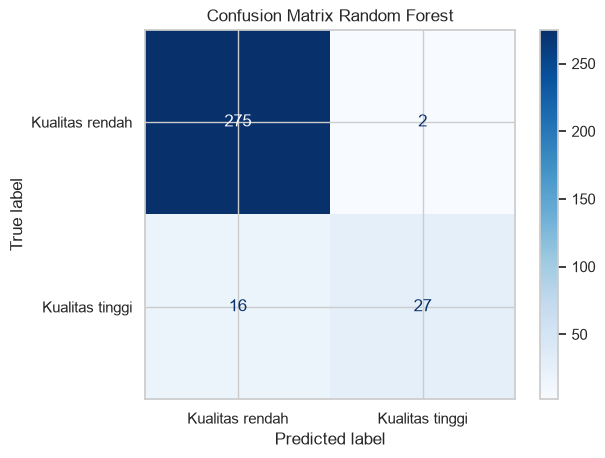

In [66]:
# Membuat confusion matrix untuk melihat hasil klasifikasi tiap kelas.
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Kualitas rendah", "Kualitas tinggi"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix Random Forest")
plt.show()

## 10. Kesimpulan sementara

Jika cell training selesai tanpa error, model sudah berhasil dilatih menggunakan data latih. Ini **belum menunjukkan seberapa baik model memprediksi data baru**; pengukuran performa termasuk evaluasi dan sengaja belum dilakukan pada tahap ini.

### Catatan sumber dan adaptasi
Notebook referensi Kaggle menggunakan jalur file khusus lingkungan Kaggle dan pada bagian model mencampurkan pendekatan regresi dengan target yang telah diubah menjadi kelas. Notebook ini disesuaikan untuk file lokal di VS Code, menggunakan target klasifikasi yang eksplisit, membuang kolom indeks tambahan, dan memisahkan data sebelum training.